<a href="https://colab.research.google.com/github/blaqkali/Chat/blob/main/chat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# pinn.py
# Conventional Physics-Informed Neural Network for the 2D Poisson equation

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

In [ ]:
# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")  # Suitable for our current CPU-only PyTorch setup

# Number of points used to train the PINN
N_INTERIOR = 1000
N_BOUNDARY = 400
EPOCHS = 2000
LEARNING_RATE = 1e-3


In [ ]:
# --------------------------------------------------
# 2. Define the neural network
# --------------------------------------------------

class PINN(nn.Module):
    def __init__(self):
        super().__init__()

        # Input: x and y coordinates
        # Output: predicted solution u(x,y)
        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, xy):
        return self.network(xy)


model = PINN().to(device)

# Adam updates the trainable neural-network parameters
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE
)


In [ ]:
# --------------------------------------------------
# 3. Generate collocation points
# --------------------------------------------------

# Interior points: points inside the square domain
xy_interior = torch.rand(
    N_INTERIOR, 2, device=device
)

# Boundary points: points on the four edges of the square
n_edge = N_BOUNDARY // 4

edge_bottom = torch.cat([
    torch.rand(n_edge, 1), torch.zeros(n_edge, 1)
], dim=1)

edge_top = torch.cat([
    torch.rand(n_edge, 1), torch.ones(n_edge, 1)
], dim=1)

edge_left = torch.cat([
    torch.zeros(n_edge, 1), torch.rand(n_edge, 1)
], dim=1)

edge_right = torch.cat([
    torch.ones(n_edge, 1), torch.rand(n_edge, 1)
], dim=1)

xy_boundary = torch.cat([
    edge_bottom, edge_top, edge_left, edge_right
], dim=0).to(device)

# The prescribed boundary solution is zero
u_boundary = torch.zeros(
    xy_boundary.shape[0], 1, device=device
)


In [ ]:
# --------------------------------------------------
# 4. Define the PDE residual using automatic differentiation
# --------------------------------------------------

def pde_residual(xy):
    # Enable differentiation with respect to x and y
    xy = xy.detach().clone().requires_grad_(True)

    # Neural network prediction
    u = model(xy)

    # First derivatives: du/dx and du/dy
    gradients = torch.autograd.grad(
        u, xy,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = gradients[:, 0:1]
    u_y = gradients[:, 1:2]

    # Second derivatives: d²u/dx² and d²u/dy²
    u_xx = torch.autograd.grad(
        u_x, xy,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0][:, 0:1]

    u_yy = torch.autograd.grad(
        u_y, xy,
        grad_outputs=torch.ones_like(u_y),
        create_graph=True
    )[0][:, 1:2]

    # Right-hand side of the Poisson equation
    x = xy[:, 0:1]
    y = xy[:, 1:2]
    f = -2.0 * np.pi**2 * torch.sin(np.pi * x) * torch.sin(np.pi * y)

    # PDE: u_xx + u_yy = f
    # Therefore, the residual should approach zero
    residual = u_xx + u_yy - f

    return residual



In [ ]:
# --------------------------------------------------
# 5. Train the PINN
# --------------------------------------------------

loss_history = []
start_time = time.time()

for epoch in range(EPOCHS):

    optimizer.zero_grad()

    # Physics loss: the network should satisfy the PDE
    residual = pde_residual(xy_interior)
    loss_pde = torch.mean(residual**2)

    # Boundary loss: the predicted solution should equal zero
    u_pred_boundary = model(xy_boundary)
    loss_boundary = torch.mean(
        (u_pred_boundary - u_boundary)**2
    )

    # Total loss combines the PDE and boundary losses
    loss = loss_pde + loss_boundary

    # Backpropagation and parameter updates
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"PDE loss: {loss_pde.item():.6e} | "
            f"Boundary loss: {loss_boundary.item():.6e} | "
            f"Total loss: {loss.item():.6e}"
        )

training_time = time.time() - start_time

print(f"\nTraining time: {training_time:.2f} seconds")


Epoch    0 | PDE loss: 9.772013e+01 | Boundary loss: 2.110084e-02 | Total loss: 9.774123e+01
Epoch  200 | PDE loss: 2.399209e+00 | Boundary loss: 1.114473e+00 | Total loss: 3.513681e+00
Epoch  400 | PDE loss: 8.589763e-02 | Boundary loss: 2.348360e-02 | Total loss: 1.093812e-01
Epoch  600 | PDE loss: 4.874913e-02 | Boundary loss: 1.891477e-02 | Total loss: 6.766390e-02
Epoch  800 | PDE loss: 3.627877e-02 | Boundary loss: 1.776577e-02 | Total loss: 5.404454e-02
Epoch 1000 | PDE loss: 2.749603e-02 | Boundary loss: 1.617610e-02 | Total loss: 4.367213e-02
Epoch 1200 | PDE loss: 2.010462e-02 | Boundary loss: 1.472299e-02 | Total loss: 3.482760e-02
Epoch 1400 | PDE loss: 1.380201e-02 | Boundary loss: 1.342778e-02 | Total loss: 2.722979e-02
Epoch 1600 | PDE loss: 9.443868e-03 | Boundary loss: 1.241233e-02 | Total loss: 2.185620e-02
Epoch 1800 | PDE loss: 6.766302e-03 | Boundary loss: 1.170948e-02 | Total loss: 1.847579e-02

Training time: 21.94 seconds


In [ ]:
# --------------------------------------------------
# 6. Evaluate against the exact solution
# --------------------------------------------------

# Create a regular grid for visualisation
n_test = 101
x_values = np.linspace(0, 1, n_test)
y_values = np.linspace(0, 1, n_test)
X, Y = np.meshgrid(x_values, y_values)

# Convert grid coordinates into a PyTorch tensor
xy_test = torch.tensor(
    np.column_stack((X.ravel(), Y.ravel())),
    dtype=torch.float32,
    device=device
)

# Evaluate the trained neural network
model.eval()
with torch.no_grad():
    U_pred = model(xy_test).cpu().numpy().reshape(X.shape)

# Calculate the exact solution
U_exact = np.sin(np.pi * X) * np.sin(np.pi * Y)

# Absolute error at each grid point
absolute_error = np.abs(U_pred - U_exact)

# Root mean square error and relative L2 error
rmse = np.sqrt(np.mean((U_pred - U_exact)**2))
relative_l2 = (
    np.linalg.norm(U_pred - U_exact)
    / np.linalg.norm(U_exact)
)

print(f"RMSE: {rmse:.6e}")
print(f"Relative L2 error: {relative_l2:.6e}")


RMSE: 6.376523e-02
Relative L2 error: 1.288058e-01


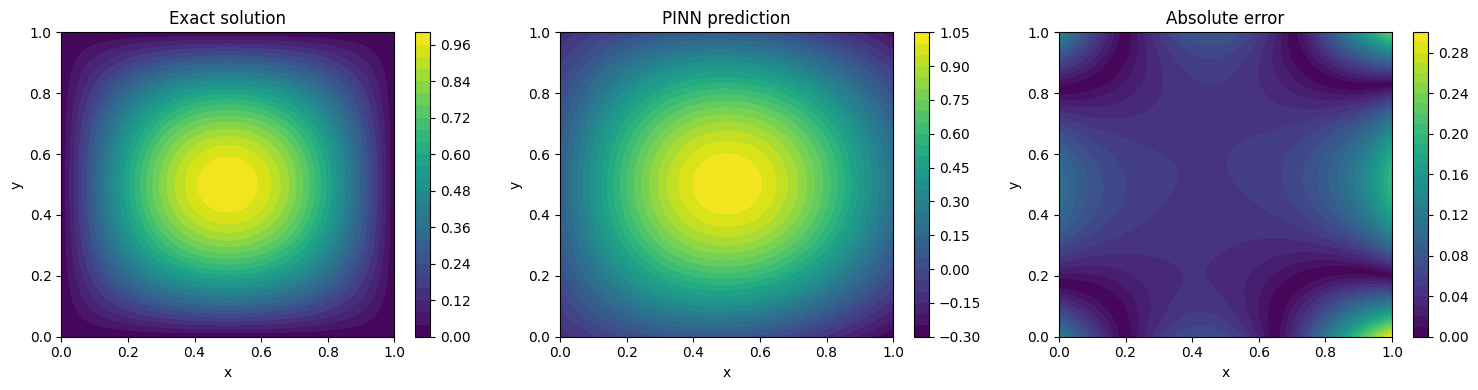

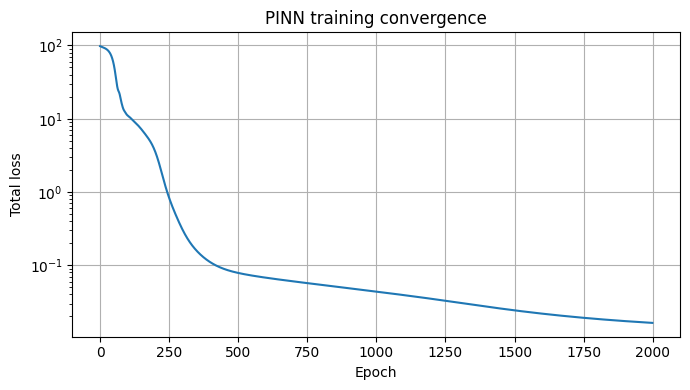

In [ ]:
# --------------------------------------------------
# 7. Visualise the results
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plots = [
    (U_exact, "Exact solution"),
    (U_pred, "PINN prediction"),
    (absolute_error, "Absolute error")
]

for ax, (data, title) in zip(axes, plots):
    contour = ax.contourf(X, Y, data, levels=30)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.colorbar(contour, ax=ax)

plt.tight_layout()
plt.show()

# Plot the training loss
plt.figure(figsize=(7, 4))
plt.semilogy(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("PINN training convergence")
plt.grid(True)
plt.tight_layout()
plt.show()